In [20]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

def load_data(filepath):
    """Load data from .sav file, return pandas dataframe and column list."""
    data = pd.read_spss(filepath)
    cols = [f"k{i}" for i in range(1, 21) if f"k{i}" in data.columns]
    return data, cols

DATA_PATH = Path("data") / "Annual 2005-2011_START.sav"
data, cols = load_data(DATA_PATH)

In [21]:
def tune_hampel_c(df: pd.DataFrame, cols: list[str], target_min: float = 0.05, target_max: float = 0.08) -> float:
    """Finds optimal c to dismiss target_min-target_max of outlier data."""
    low, high = 1.0, 100.0
    c = 1

    for _ in range(30):
        _, outliers = apply_hampel_filter(df, cols, c=c)
        ratio = len(outliers) / len(df)

        if target_min <= ratio <= target_max:
            break

        if ratio > target_max:
            low = c
        else:
            high = c
        c = (low + high) / 2.0

    return c

def apply_hampel_filter(df: pd.DataFrame, cols: list[str], c: float = 30.0):
    """Return filtered dataframe and outliers based on hampel filter with given c (30 by default)."""
    medians = df[cols].median()
    mads = abs(df[cols] - medians).median()

    mask = (df[cols] > medians + c * mads) | (df[cols] < medians - c * mads)
    is_outlier = mask.any(axis=1)
    df_clean = df[~is_outlier].copy()
    outliers = df[is_outlier].copy()
    return df_clean, outliers

best_c = tune_hampel_c(data, cols, target_min=0.05, target_max=0.08)
print("Applied c to Hampel filter:", round(best_c, 2))

df_clean, outliers = apply_hampel_filter(data, cols, c=best_c)
df_clean.info()
outliers.info()

Applied c to Hampel filter: 38.12
<class 'pandas.DataFrame'>
Index: 2537 entries, 1 to 2694
Data columns (total 23 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Cреднеспис.числ.работн  2537 non-null   float64
 1   k1                      2537 non-null   float64
 2   k2                      2537 non-null   float64
 3   k3                      2537 non-null   float64
 4   k4                      2537 non-null   float64
 5   k4_new                  1449 non-null   float64
 6   k5                      2537 non-null   float64
 7   k6                      2537 non-null   float64
 8   k7                      2537 non-null   float64
 9   k8                      2537 non-null   float64
 10  k9                      2537 non-null   float64
 11  k10                     2537 non-null   float64
 12  k11                     2537 non-null   float64
 13  k12                     2537 non-null   float64
 14  k13                   

In [22]:
def compute_descriptive_stats(df: pd.DataFrame, cols: list[str]) -> pd.DataFrame:
    """Generate a descriptive dataframe consisting of min, max, mean, median, standard deviation, skewness, and kurtosis for each column."""
    return pd.DataFrame({
        "min": df[cols].min(),
        "max": df[cols].max(),
        "mean": df[cols].mean(),
        "median": df[cols].median(),
        "standard deviation": df[cols].std(),
        "skewness": df[cols].skew(),
        "kurtosis": df[cols].kurtosis()
    })

desc_table = compute_descriptive_stats(df_clean, cols + ['k4_new', 'Cреднеспис.числ.работн'])
display(desc_table.round(4))

,min,max,mean,median,standard deviation,skewness,kurtosis
k1,0.2483,14.3383,1.8650,1.4556,1.3468,2.8492,12.7649
k2,0.0000,1.8999,0.1785,0.0518,0.3021,2.8152,8.5742
k3,0.0098,5.5966,0.7359,0.5210,0.6946,2.5889,9.2303
k4,-4.5699,0.9269,0.0255,0.1388,0.6117,-2.3236,9.2560
k5,0.0099,1.0837,0.3545,0.3310,0.1955,0.5383,-0.2713
k6,0.0000,1.0000,0.2399,0.1884,0.2124,0.9925,0.4404
k7,0.0000,1.0000,0.1766,0.0784,0.2244,1.4980,1.5933
k8,0.0538,0.9901,0.6479,0.6704,0.1932,-0.4983,-0.3948
k9,0.0593,99.5596,6.4821,4.6184,6.7253,3.8130,27.1081
k10,0.0400,11.8343,0.8389,0.6218,0.8133,3.8579,27.5675


In [23]:
def run_normality_tests(df: pd.DataFrame, test_cols: list[str]) -> pd.DataFrame:
    """
    Test normality using Shapiro-Wilk, Kolmogorov-Smirnov, and Chi-Square.
    Number of bins for Chi-Square is calculated dynamically using Sturges' formula: k = ceil(1 + log2(n)).
    """
    results = []
    for col in test_cols:
        series = df[col].dropna()
        n = len(series)

        _, p_shapiro = stats.shapiro(series)

        norm_dist = stats.norm(loc=series.mean(), scale=series.std())
        _, p_ks = stats.kstest(series, cdf=norm_dist.cdf)

        n_bins = int(np.ceil(1 + np.log2(n)))
        quantiles = np.linspace(0, 1, n_bins + 1)
        exp_freq = np.full(n_bins, n / n_bins)

        bin_edges = norm_dist.ppf(quantiles)
        obs_freq, _ = np.histogram(series, bins=bin_edges)

        _, p_chi2 = stats.chisquare(f_obs=obs_freq, f_exp=exp_freq, ddof=2)

        results.append({
            "col": col,
            "bins_chi2": n_bins,
            "p_shapiro": f"{p_shapiro:.2e}",
            "p_ks": f"{p_ks:.2e}",
            "p_chi2": f"{p_chi2:.2e}",
            "is_normal": "Yes" if min(p_shapiro, p_ks, p_chi2) >= 0.05 else "No"
        })

    return pd.DataFrame(results)

all_cols = cols + ['k4_new', 'Cреднеспис.числ.работн']

normality_table = run_normality_tests(df_clean, all_cols)
display(normality_table)

,col,bins_chi2,p_shapiro,p_ks,p_chi2,is_normal
0,k1,13,8.29e-53,8.44e-72,0.00e+00,No
1,k2,13,3.95e-60,5.20e-173,0.00e+00,No
2,k3,13,1.98e-52,6.11e-71,0.00e+00,No
3,k4,13,3.75e-46,1.15e-30,4.72e-104,No
4,k5,13,6.53e-23,7.07e-08,1.21e-35,No
5,k6,13,4.07e-37,1.90e-37,1.80e-140,No
6,k7,13,1.54e-49,4.66e-104,0.00e+00,No
7,k8,13,1.28e-22,6.01e-07,8.54e-34,No
8,k9,13,3.10e-56,5.83e-74,0.00e+00,No
9,k10,13,4.22e-56,5.85e-69,0.00e+00,No


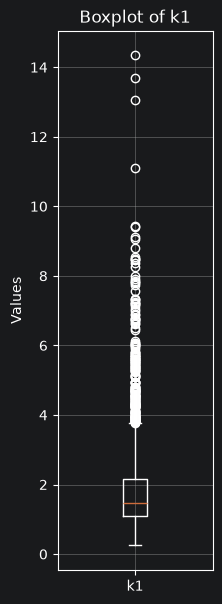

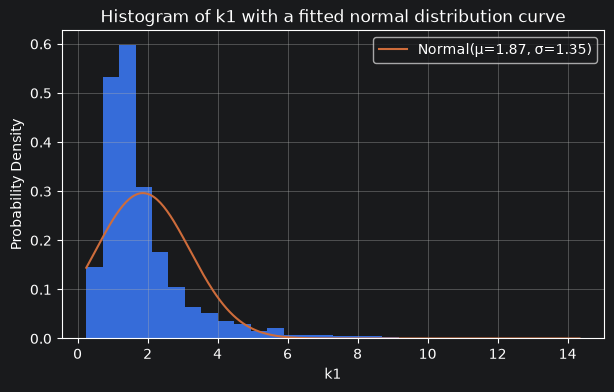

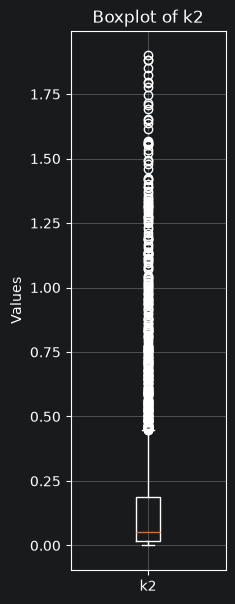

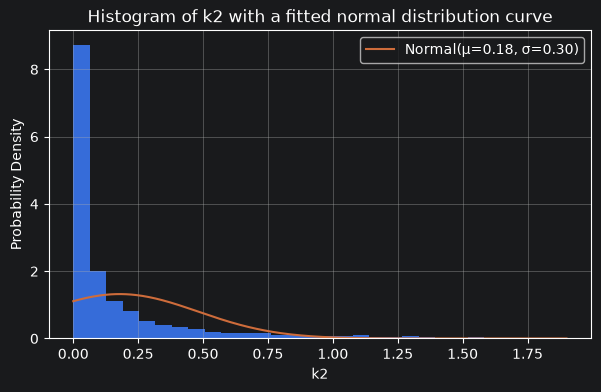

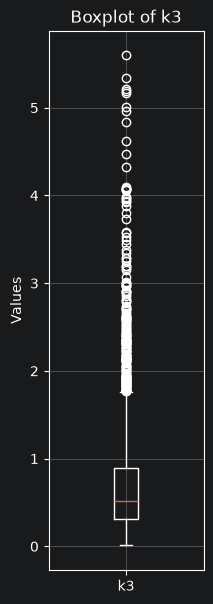

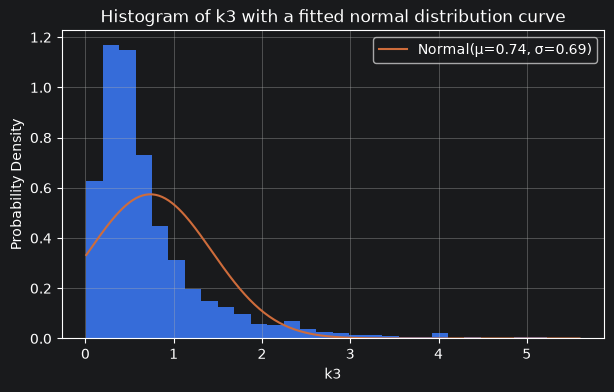

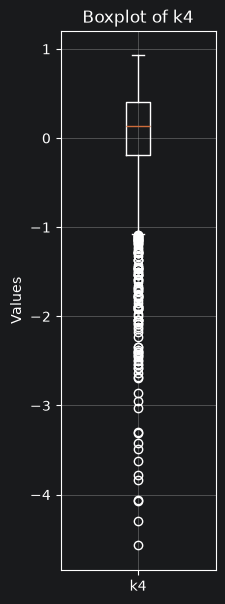

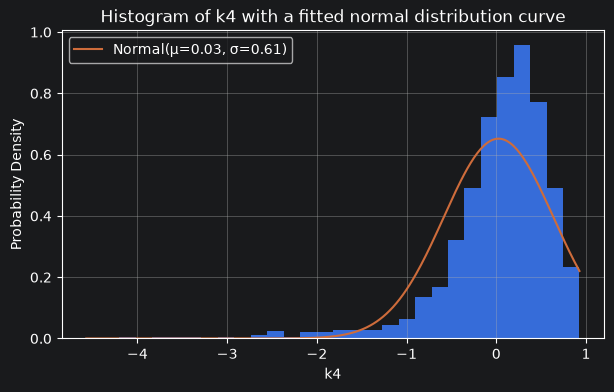

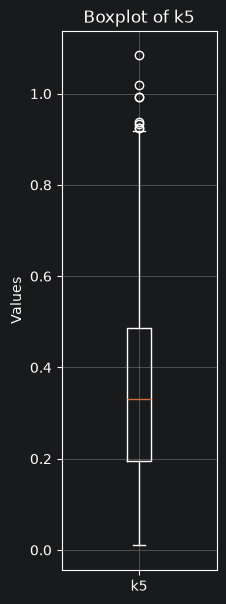

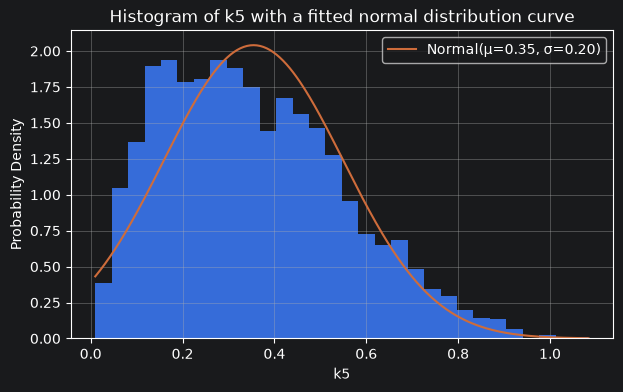

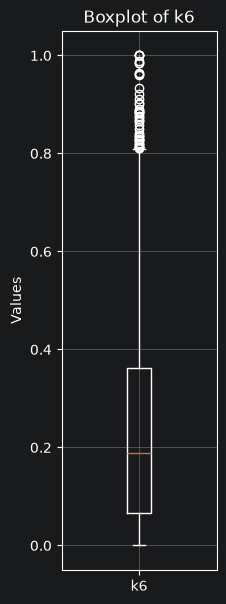

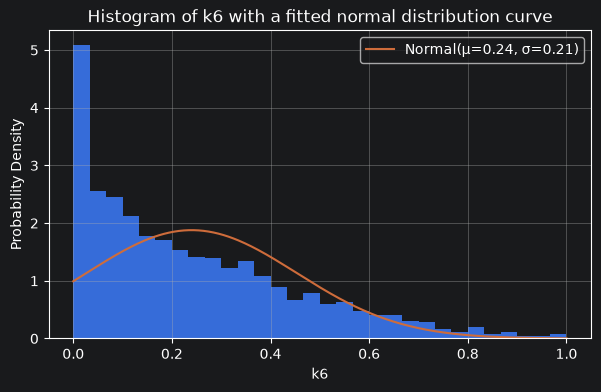

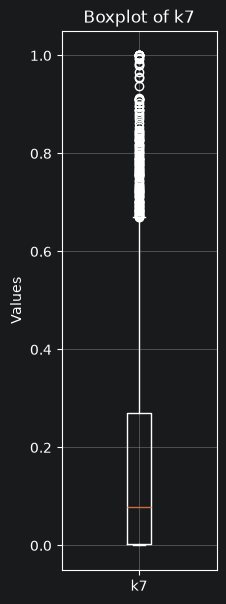

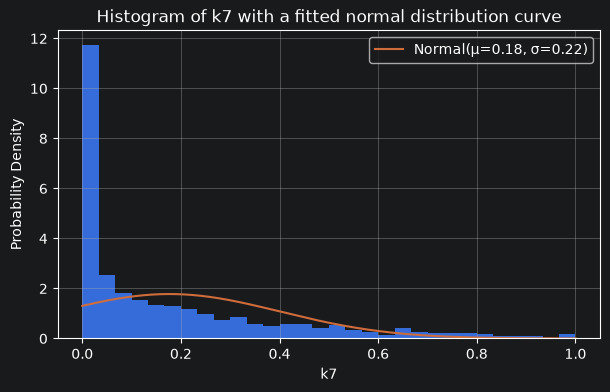

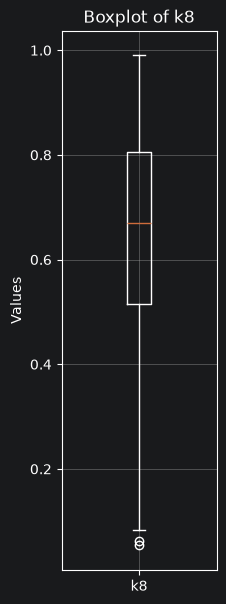

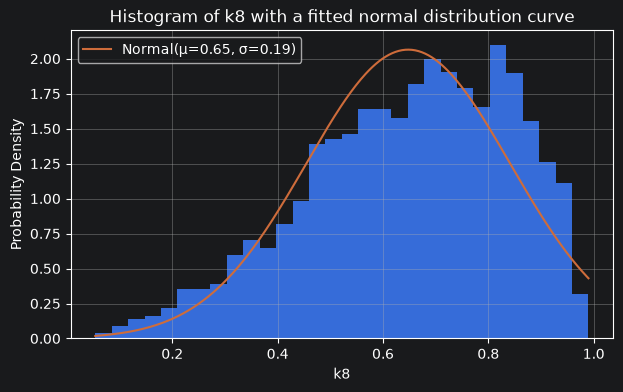

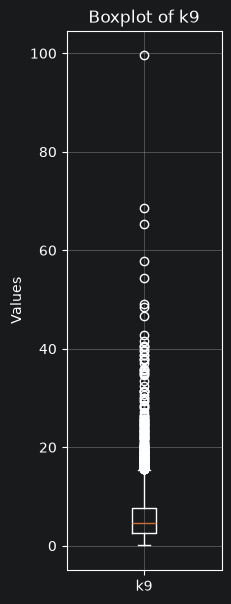

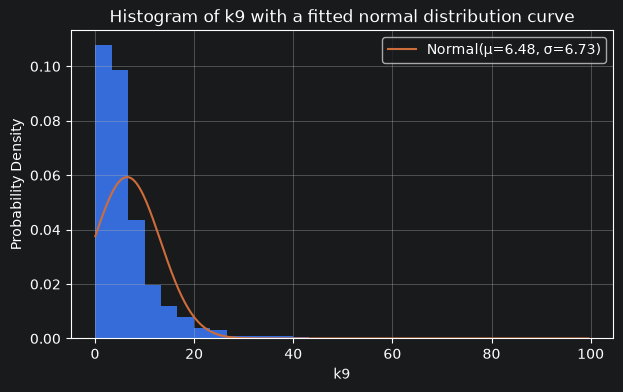

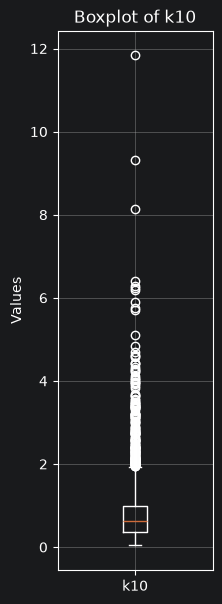

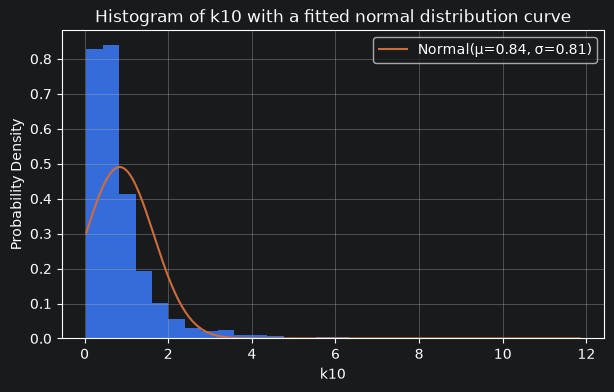

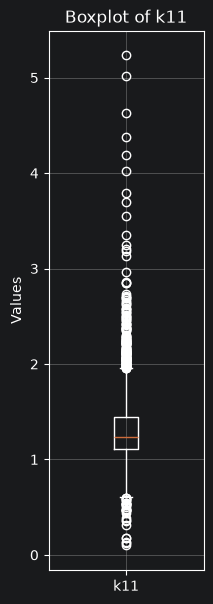

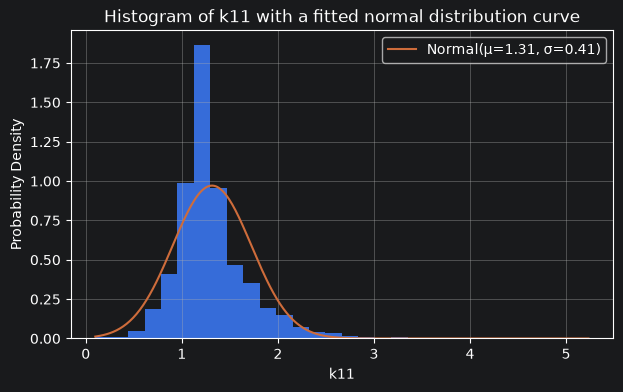

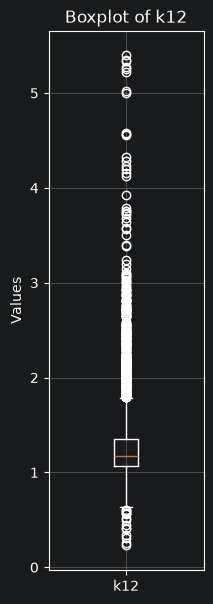

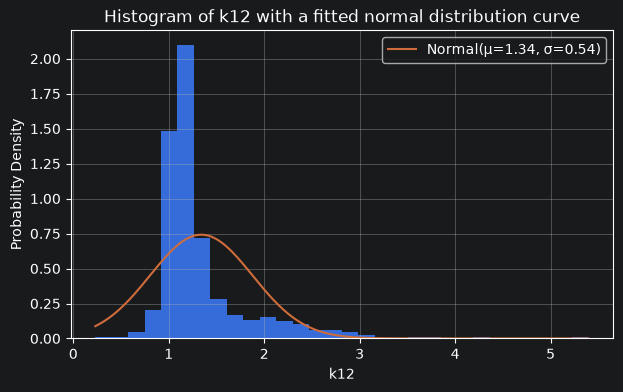

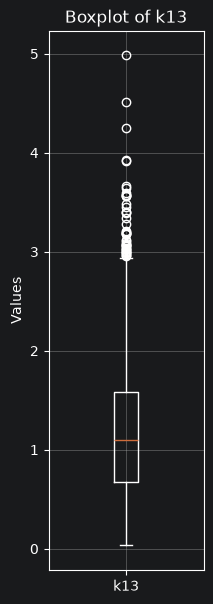

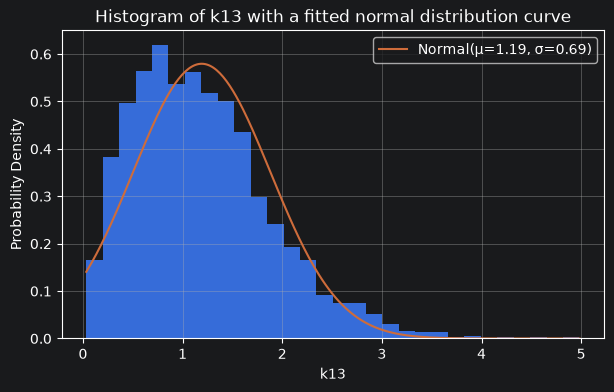

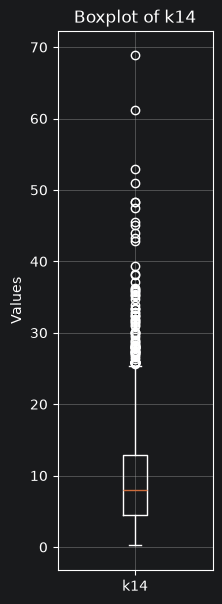

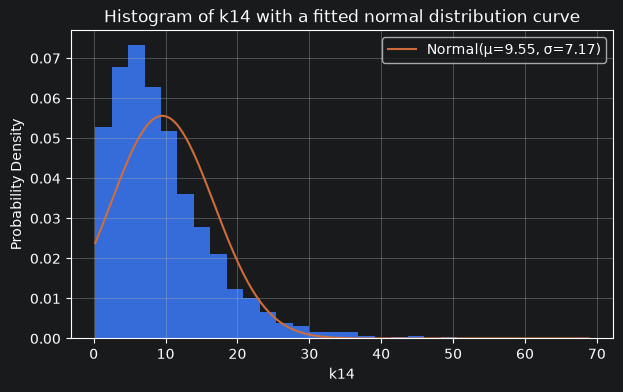

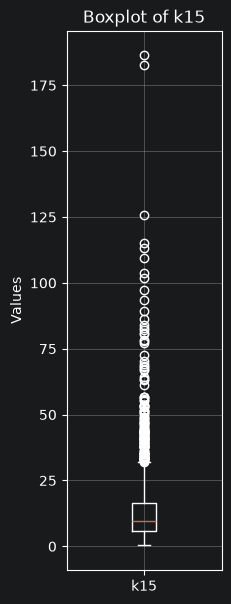

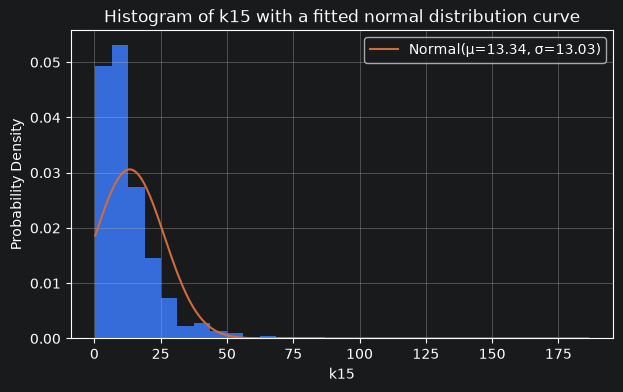

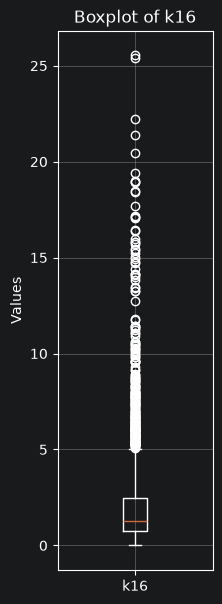

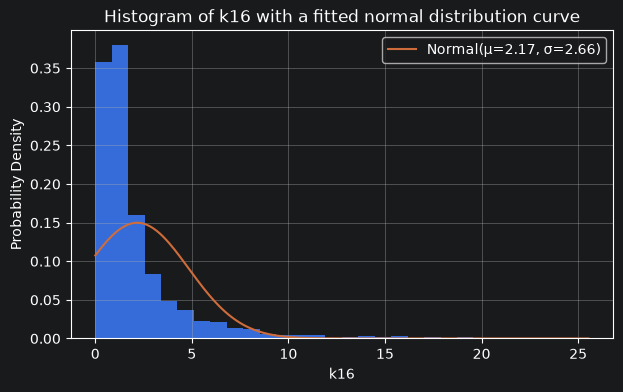

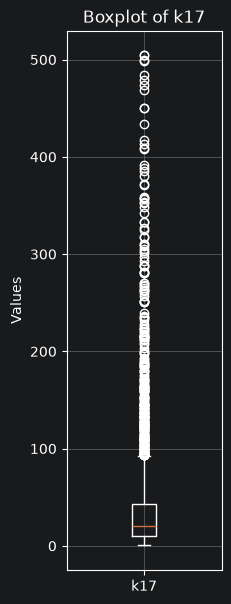

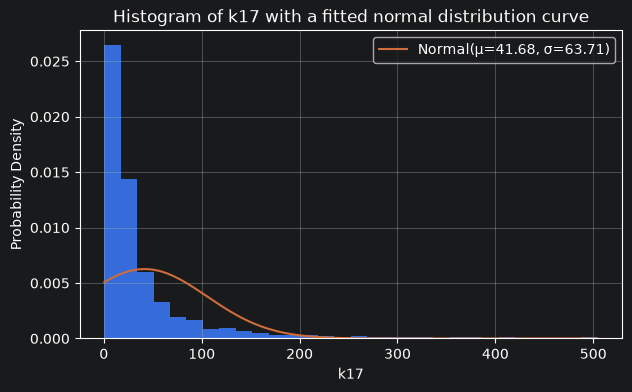

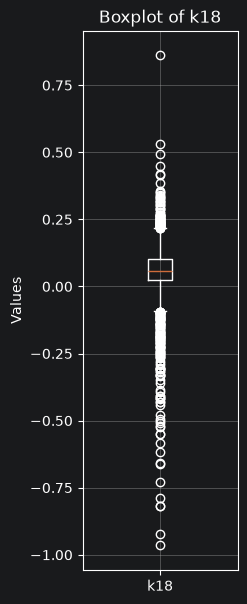

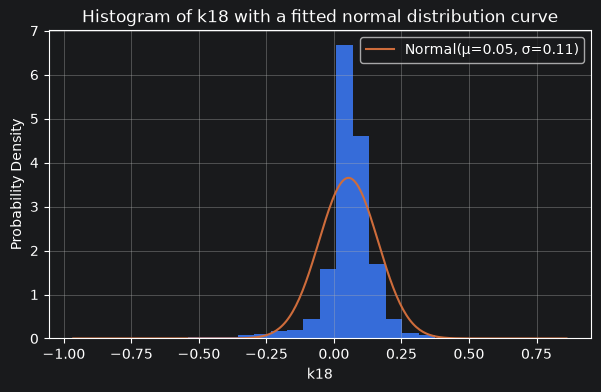

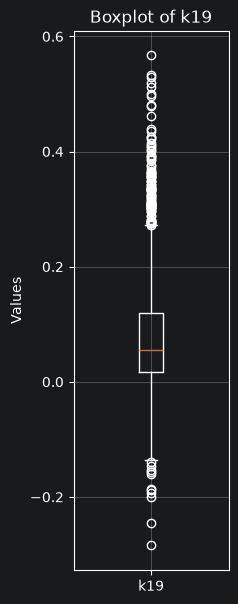

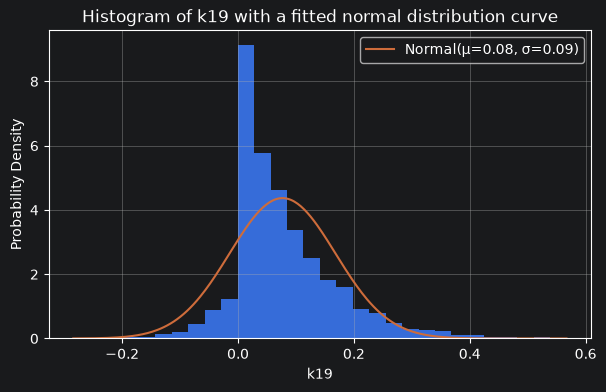

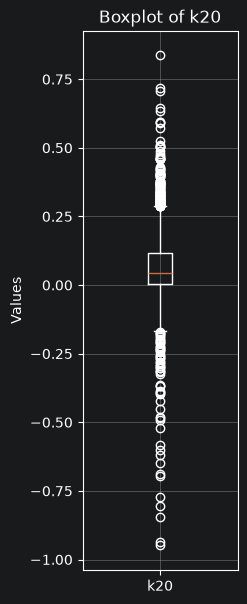

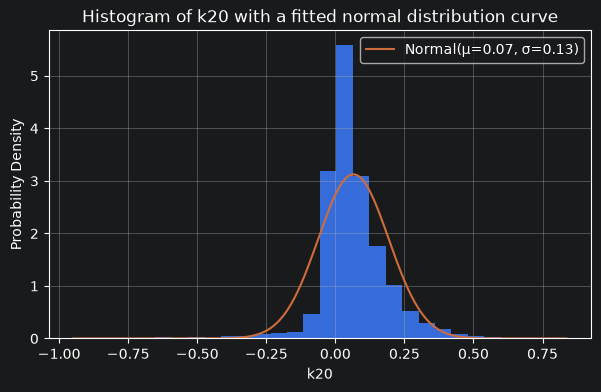

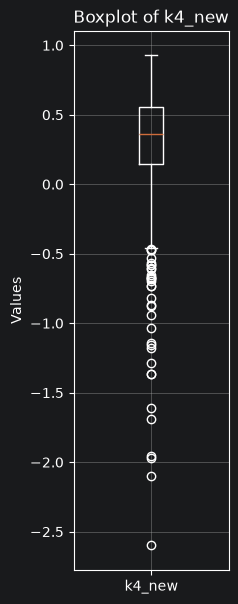

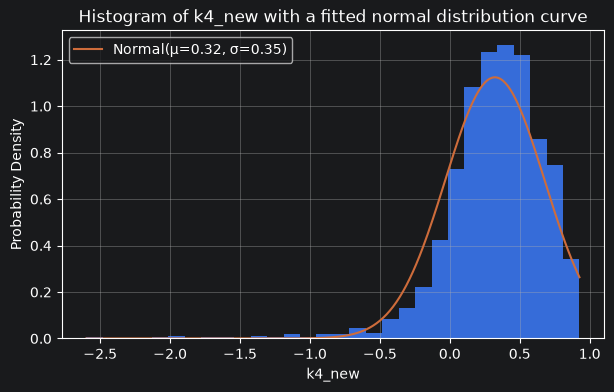

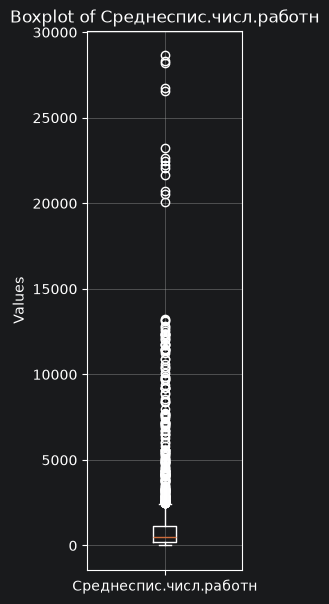

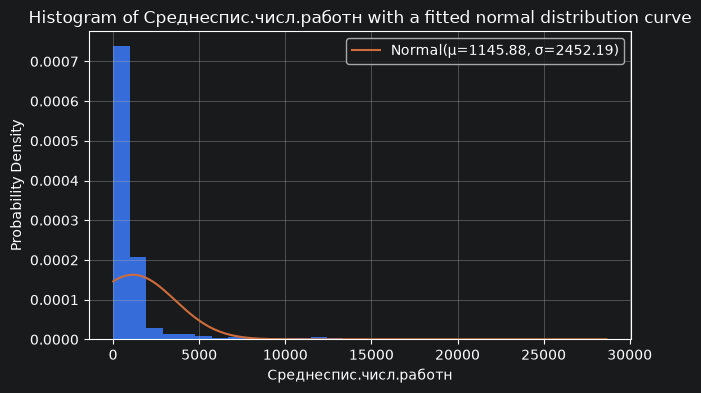

In [24]:
def plot_distributions(df: pd.DataFrame, target_cols: list[str]):
    """Displays a boxplot and constructs a histogram with a fitted normal distribution curve for each column"""
    for col in target_cols:
        series = df[col].dropna()
        mu = series.mean()
        sigma = series.std()

        plt.figure(figsize=(2, 7))
        plt.boxplot(series, tick_labels=[col])
        plt.title(f"Boxplot of {col}")
        plt.ylabel("Values")
        plt.grid(True)
        plt.show()

        plt.figure(figsize=(7, 4))
        plt.hist(series, bins=30, density=True)

        x_axis = np.linspace(series.min(), series.max(), 300)
        normal_curve = stats.norm.pdf(x_axis, loc=mu, scale=sigma)
        plt.plot(x_axis, normal_curve, label=f'Normal(μ={mu:.2f}, σ={sigma:.2f})')

        plt.title(f"Histogram of {col} with a fitted normal distribution curve", fontsize=12)
        plt.xlabel(col)
        plt.ylabel("Probability Density")
        plt.legend()
        plt.grid(True)
        plt.show()

plot_distributions(df_clean, all_cols)

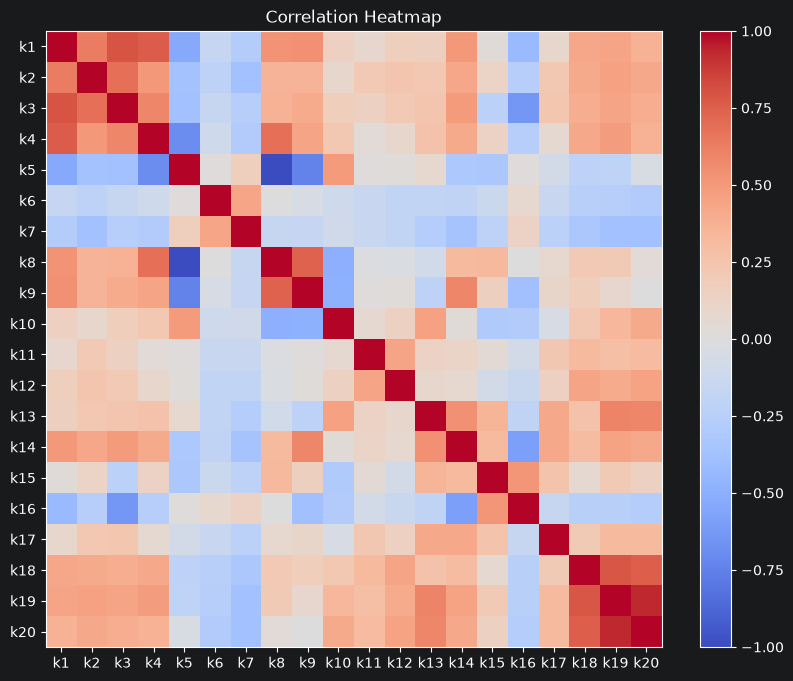

Collinear pairs (|r| >= 0.95):
• k5 and k8: r = -0.9972

Strongly correlated pairs (0.70 <= |r| < 0.95):
• k1 and k3: r = 0.7891
• k1 and k4: r = 0.7607
• k5 and k9: r = -0.7389
• k8 and k9: r = 0.7386
• k18 and k19: r = 0.7864
• k18 and k20: r = 0.7514
• k19 and k20: r = 0.9351


In [25]:
def run_correlation_analysis(df: pd.DataFrame, cols: list[str]):
    corr = df[cols].corr(method="spearman")

    plt.figure(figsize=(10, 8))
    plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
    plt.colorbar()
    plt.xticks(range(len(cols)), cols)
    plt.yticks(range(len(cols)), cols)
    plt.title("Correlation Heatmap")
    plt.show()

    strong_corr = [(f"k{i}", f"k{j}", round(corr.loc[f"k{i}", f"k{j}"], 4))
                   for i in range(1, 21) for j in range(i + 1, 21)
                   if 0.70 <= abs(corr.loc[f"k{i}", f"k{j}"]) < 0.95]
    collinear = [(f"k{i}", f"k{j}", round(corr.loc[f"k{i}", f"k{j}"], 4))
                        for i in range(1, 21) for j in range(i + 1, 21)
                        if abs(corr.loc[f"k{i}", f"k{j}"]) >= 0.95]
    return strong_corr, collinear

strong, collinear = run_correlation_analysis(df_clean, cols)

print("Collinear pairs (|r| >= 0.95):")
for c1, c2, r in collinear:
    print(f"• {c1} and {c2}: r = {r}")

print("\nStrongly correlated pairs (0.70 <= |r| < 0.95):")
for c1, c2, r in strong:
    print(f"• {c1} and {c2}: r = {r}")

df_clean.to_csv('data.csv', index=False)